# 08 — Pretraining Loop

## Terms & Definitions
- **Pretraining**: training a language model from randomly-initialized weights on raw (unlabeled) text, using the next-token-prediction objective.
- **Epoch**: one full pass through the training data (less commonly tracked in LLM pretraining than in smaller ML tasks, since we usually just sample random chunks — see below).
- **Batch**: a group of training examples processed together in one forward/backward pass — bigger batches give a smoother (less noisy) gradient estimate but cost more compute per step.
- **Learning rate (LR) schedule**: how the optimizer's step size changes over training — typically warmup (small steps  at first, since random initial weights make big updates risky) followed by decay (smaller steps as the model converges).
- **Gradient clipping**: capping the norm of the gradient before the optimizer step, to prevent rare huge/unstable updates from derailing training.
- **Checkpoint**: a saved snapshot of a model's weights, so training can be resumed or the model can be reloaded later without retraining.

## The Training Loop

Every stage from here forward (pretraining, CPT, SFT) uses the exact same loop shape from notebook 00, just with different data and (for SFT) a different loss mask:

```
for step in range(num_steps):
    x, y = get_batch(...)              # sample a batch of (input, target) sequences
    logits, loss = model(x, targets=y)  # forward pass + cross-entropy loss
    optimizer.zero_grad()
    loss.backward()                     # compute gradients
    clip_grad_norm_(...)                # prevent exploding updates
    optimizer.step()                    # apply the LR-scheduled update
```

For pretraining specifically: `x` is a random chunk of the corpus, and `y` is that same chunk shifted one token to the right — so at every position, the target is simply "the token that actually comes next" (see `src/data.py: get_batch`).

## Why Warmup + Cosine Decay?
- **Warmup**: at step 0, the model's weights are random and its loss landscape is poorly understood by the optimizer yet — large steps early can push weights somewhere bad. Warmup ramps the LR up gradually over the first N steps.
- **Cosine decay**: after warmup, LR follows a cosine curve down toward a small minimum, rather than staying high (which would keep the model "jittering" instead of settling) or dropping to zero (which would stop learning entirely). This exact schedule is what GPT-2/GPT-3 and most modern LLM pretraining uses (see `src/train_utils.py: get_lr`).

## A Practical Note on This Machine
This machine has no CUDA GPU and — as of writing this curriculum — was also under real memory pressure from other running applications (browser, other services), which slows CPU throughput noticeably (benchmarked at roughly 1-1.3 seconds per training step at batch_size=16, block_size=128 on this machine). The step counts and batch sizes below were chosen to complete in a few minutes even under that pressure -- in a quick 150-step benchmark, loss already dropped from ~9.09 (the untrained baseline) to ~5.3. If you're running with more headroom (a dedicated machine, or a GPU), feel free to increase `n_steps` and `batch_size` in the config cell below — the training loop itself doesn't change, it will just converge further.


In [1]:
import sys
sys.path.insert(0, "..")

import time
import torch

from src.model import GPTMicro, GPTConfig
from src.data import (
    load_electricity_for_boys, train_bpe_tokenizer, encode_corpus_to_tensor,
    get_batch, get_train_val_split, set_seed,
)
from src.train_utils import get_lr, estimate_loss, save_checkpoint, plot_losses

torch.set_num_threads(6)  # tune this to your machine's core count; see notebook markdown above
set_seed(1337)


## Load Data and Tokenizer


In [2]:
text = load_electricity_for_boys()
tokenizer = train_bpe_tokenizer(text, vocab_size=8000)
data = encode_corpus_to_tensor(text, tokenizer)
train_data, val_data = get_train_val_split(data, val_fraction=0.1)

print(f"corpus: {len(text):,} characters -> {len(data):,} tokens")
print(f"train:  {len(train_data):,} tokens")
print(f"val:    {len(val_data):,} tokens")





corpus: 221,805 characters -> 53,625 tokens
train:  48,262 tokens
val:    5,363 tokens


## Build the Model


In [3]:
config = GPTConfig(
    vocab_size=8000,
    block_size=128,   # shorter than notebook 07's 256, to keep CPU training fast
    n_layer=6,
    n_head=8,
    n_embd=480,
    dropout=0.1,
)
model = GPTMicro(config)
print(f"model: {model.num_params()/1e6:.2f}M parameters")


model: 20.53M parameters


## Training Configuration


In [4]:
batch_size = 16
n_steps = 300
warmup_steps = 30
max_lr = 3e-4
eval_every = 50
eval_iters = 10

optimizer = torch.optim.AdamW(model.parameters(), lr=max_lr, weight_decay=0.01)
print(f"training for {n_steps} steps, batch_size={batch_size}, block_size={config.block_size}")


training for 300 steps, batch_size=16, block_size=128


## Run Pretraining

This is the real training loop — watch the loss column drop from near $\ln(8000) \approx 9.0$ (the untrained baseline from notebook 07) toward something much smaller as the model learns the statistical structure of *Electricity for Boys*.


In [5]:
train_losses = []
val_losses = []

t0 = time.time()
for step in range(n_steps):
    lr = get_lr(step, warmup_steps, n_steps, max_lr)
    for g in optimizer.param_groups:
        g["lr"] = lr

    x, y = get_batch(train_data, config.block_size, batch_size, device="cpu")
    logits, loss = model(x, targets=y)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    train_losses.append(loss.item())

    if step % eval_every == 0 or step == n_steps - 1:
        val_loss = estimate_loss(model, val_data, config.block_size, batch_size, "cpu", eval_iters, get_batch)
        val_losses.append(val_loss)
        elapsed = time.time() - t0
        print(f"step {step:4d}/{n_steps}  train_loss {loss.item():.3f}  val_loss {val_loss:.3f}  lr {lr:.2e}  ({elapsed:.0f}s elapsed)")

print(f"\ntraining complete in {time.time()-t0:.0f}s")


step    0/300  train_loss 9.093  val_loss 8.841  lr 1.00e-05  (3s elapsed)
step   50/300  train_loss 5.961  val_loss 5.213  lr 2.96e-04  (58s elapsed)
step  100/300  train_loss 5.305  val_loss 4.569  lr 2.58e-04  (111s elapsed)
step  150/300  train_loss 4.584  val_loss 4.244  lr 1.88e-04  (165s elapsed)
step  200/300  train_loss 4.600  val_loss 4.210  lr 1.12e-04  (220s elapsed)
step  250/300  train_loss 4.435  val_loss 4.211  lr 5.22e-05  (271s elapsed)
step  299/300  train_loss 4.407  val_loss 4.205  lr 3.00e-05  (326s elapsed)

training complete in 326s


step   50/300  train_loss 5.961  val_loss 5.213  lr 2.96e-04  (60s elapsed)


step  100/300  train_loss 5.305  val_loss 4.569  lr 2.58e-04  (121s elapsed)


step  150/300  train_loss 4.584  val_loss 4.244  lr 1.88e-04  (180s elapsed)


step  200/300  train_loss 4.600  val_loss 4.210  lr 1.12e-04  (240s elapsed)


step  250/300  train_loss 4.435  val_loss 4.211  lr 5.22e-05  (299s elapsed)


step  299/300  train_loss 4.407  val_loss 4.205  lr 3.00e-05  (357s elapsed)

training complete in 357s


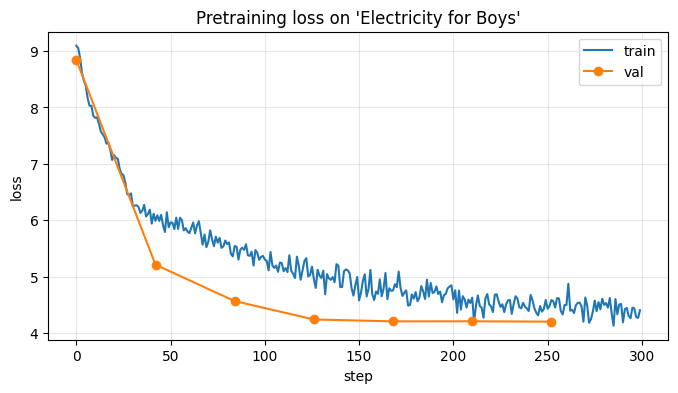

In [6]:
plot_losses(train_losses, val_losses, title="Pretraining loss on 'Electricity for Boys'")


## Save the Checkpoint

Every later notebook (09, 10, 11) loads this exact checkpoint by name, so it must be saved here before moving on.


In [7]:
path = save_checkpoint(model, "pretrained_electricity")
print(f"saved checkpoint to {path}")


saved checkpoint to /home/tyrel/projects/llm-lessons/checkpoints/pretrained_electricity.pt


## Sanity-Check: Sample Some Text

We'll do a deeper dive on sampling strategies in notebook 09, but let's take a quick look now at what the freshly pretrained model generates.


In [8]:
model.eval()
prompt = "Electricity is"
context = torch.tensor([tokenizer.encode(prompt).ids], dtype=torch.long)

generated = model.generate(context, max_new_tokens=60, temperature=0.8, top_k=40)
print(tokenizer.decode(generated[0].tolist()))


Electricity is
and the armature (C), which is called a screw (A, and then of the
from the armature (D) is a wire (B), and the other end of the post (F)
(J), which from one end of the other side, and the other, the


Don't expect polished, coherent prose — at 20M parameters trained for a few hundred steps on ~227KB of text, "success" looks like recognizable words, mostly correct spelling, and occasional short phrases that resemble the source material. That's a real, working demonstration of next-token-prediction learning happening in front of you — a meaningfully lower loss than the untrained baseline, and text that's clearly not random.

## Exercise
Increase `n_steps` (e.g. to 2000) and re-run — if you have the time/patience, you should see both a lower final loss and more locally-fluent generated text. Watch the val_loss column too: if it starts *increasing* while train_loss keeps decreasing, that's overfitting (the model is starting to memorize training-specific quirks rather than learning generalizable patterns) — a concept worth recognizing even at this toy scale.

## Summary
- Pretraining repeats: sample a batch, forward pass, compute cross-entropy loss, backward pass, clipped optimizer step — over and over.
- A warmup + cosine-decay LR schedule is standard practice and is what `src/train_utils.py: get_lr` implements.
- We trained `GPTMicro` from scratch on *Electricity for Boys* and saved the result as the `pretrained_electricity` checkpoint, which every subsequent notebook builds on.

Next: **09 — Evaluating and Sampling** (a deeper look at perplexity and decoding strategies, using this checkpoint).
